# Running Forecast command to assess if it works correctly

In [1]:
import subprocess
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [ ]:
import subprocess
import sys
import sys
from pathlib import Path

project_root = Path.cwd().parent


forecast_list = []

for i in range(2022, 2026):
    forecast_data = [
        sys.executable,
        "-m",
        "MASTER.MASTER_forecast_fields",
        "--init-date",
        f"{i}-04-01",
        "--lead-months",
        "6",
        "--member",
        "51",
        "--generate-config",
        "--active-months",
        "6",
        "7",
        "8",
        "9",
        "10",
        "11",
        "--workers",
        "10",
        # "--force-recorrect",
        # "--skip-download"
    ]

    forecast_members = [f"forecast_configs/config_m{m}.json" for m in range(51)]
    forecast_sample = [
        sys.executable,
        "-m",
        "MASTER.MASTER_storm_parallel",
        "--forecast",
        *forecast_members,
        "--basins",
        "NA",
        "--years",
        "100",
        "--loop",
        "1",
        "--workers",
        "10",
        "--outdir",
        f"Forecast_04_{i}",
    ]

    # commands = (
    #     [
    #         # [sys.executable, "-m", "MASTER.MASTER_climatology"],
    #         # [sys.executable, "-m", "MASTER.MASTER_preprocessing"],
    #     ]
    #     + forecast_data
    #     + forecast_sample
    # )
    forecast_list.append(forecast_data)
    forecast_list.append(forecast_sample)


In [ ]:

for cmd in forecast_list:
    print("Running:", " ".join(cmd))
    subprocess.run(cmd, check=True, cwd=project_root)

In [23]:
from pathlib import Path
import re
import json

import pandas as pd
import matplotlib.pyplot as plt
import pathlib


folder =Path(pathlib.Path().resolve().parent / "forecast_configs")

pattern = re.compile(r"^oni_merged_m([0-9]|[1-4][0-9]|50)\.json$")

records = {}

for path in folder.iterdir():
    match = pattern.match(path.name)
    if not match:
        continue

    m = int(match.group(1))

    with open(path, "r") as f:
        data = json.load(f)

    # data should be like {"2020-01": value, "2020-02": value, ...}
    records[f"oni_m{m}"] = data


# rows = months, columns = files
df = pd.DataFrame(records)

# Convert values to numeric
df = df.apply(pd.to_numeric, errors="coerce")

# Sort columns numerically by m index
df = df[sorted(df.columns, key=lambda x: int(x.replace("oni_m", "")))]

# Try to sort months chronologically
parsed_index = pd.to_datetime(df.index, errors="coerce")

if parsed_index.notna().all():
    df.index = parsed_index
    df = df.sort_index()
else:
    df = df.sort_index()

print(df.head())


     oni_m0    oni_m1    oni_m2   oni_m3    oni_m4    oni_m5   oni_m6  \
0 -0.670000 -0.670000 -0.670000 -0.67000 -0.670000 -0.670000 -0.67000   
1 -0.580000 -0.580000 -0.580000 -0.58000 -0.580000 -0.580000 -0.58000   
2 -0.270000 -0.270000 -0.270000 -0.27000 -0.270000 -0.270000 -0.27000   
3 -0.060000 -0.060000 -0.060000 -0.06000 -0.060000 -0.060000 -0.06000   
4  0.493307  0.514391  0.493493  0.51608  0.294148  0.492614  0.49412   

     oni_m7    oni_m8    oni_m9  ...   oni_m41   oni_m42   oni_m43   oni_m44  \
0 -0.670000 -0.670000 -0.670000  ... -0.670000 -0.670000 -0.670000 -0.670000   
1 -0.580000 -0.580000 -0.580000  ... -0.580000 -0.580000 -0.580000 -0.580000   
2 -0.270000 -0.270000 -0.270000  ... -0.270000 -0.270000 -0.270000 -0.270000   
3 -0.060000 -0.060000 -0.060000  ... -0.060000 -0.060000 -0.060000 -0.060000   
4  0.595028  0.482845  0.416472  ...  0.570449  0.524858  0.472685  0.492392   

    oni_m45   oni_m46   oni_m47   oni_m48  oni_m49   oni_m50  
0 -0.670000 -0.67

/tmp/ipykernel_963907/1612026488.py:40: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed_index = pd.to_datetime(df.index, errors="coerce")


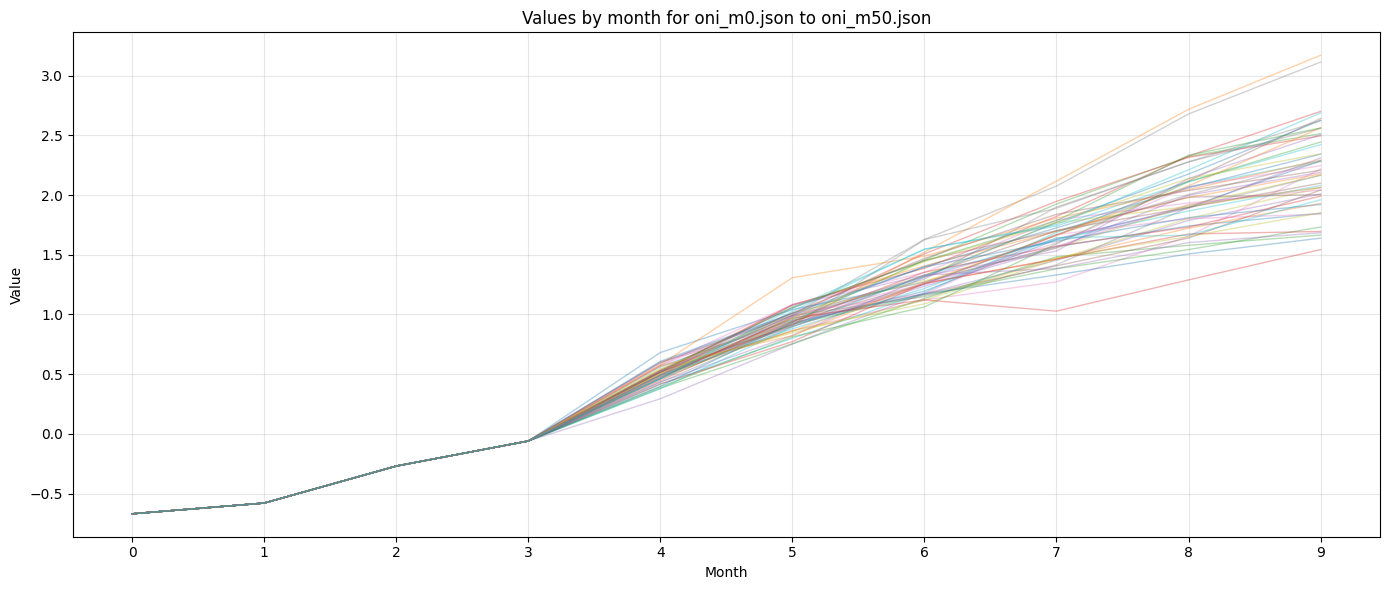

In [24]:
plt.figure(figsize=(14, 6))

for col in df.columns:
    plt.plot(df.index, df[col], alpha=0.35, linewidth=1)

plt.xlabel("Month")
plt.ylabel("Value")
plt.title("Values by month for oni_m0.json to oni_m50.json")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


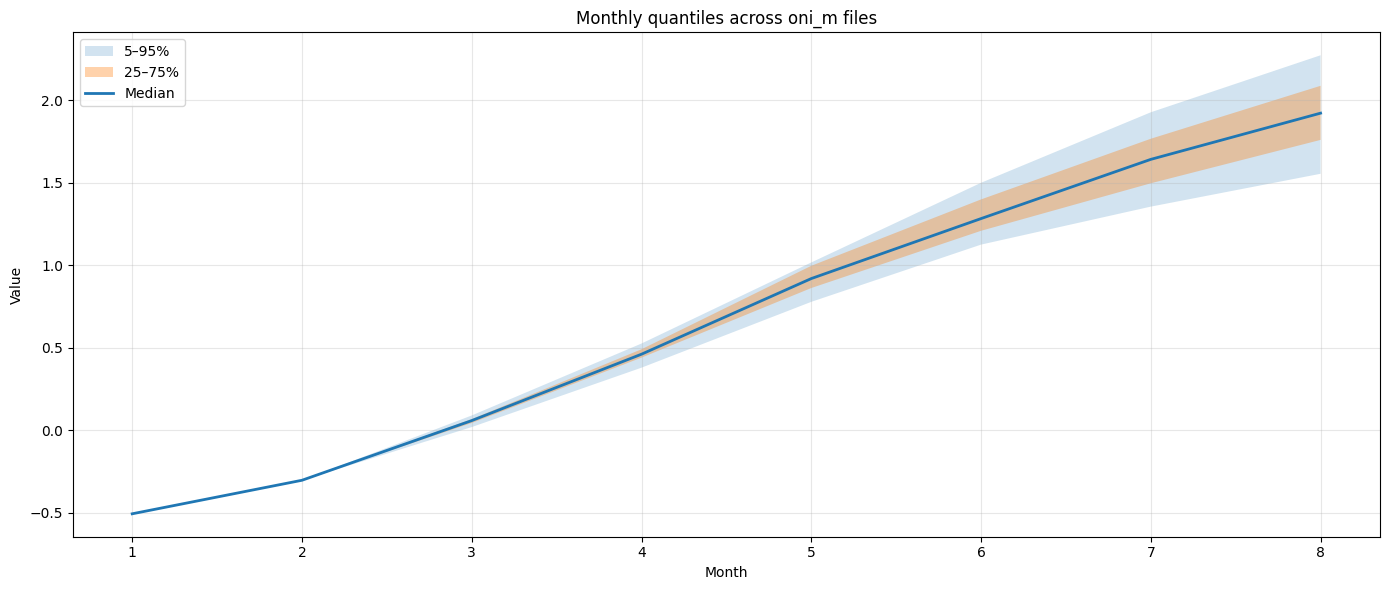

In [22]:
quantiles = df.quantile([0.05, 0.25, 0.50, 0.75, 0.95], axis=1).T
quantiles.columns = ["q05", "q25", "q50", "q75", "q95"]

plt.figure(figsize=(14, 6))

plt.fill_between(
    quantiles.index, quantiles["q05"], quantiles["q95"], alpha=0.2, label="5–95%"
)

plt.fill_between(
    quantiles.index, quantiles["q25"], quantiles["q75"], alpha=0.35, label="25–75%"
)

plt.plot(quantiles.index, quantiles["q50"], linewidth=2, label="Median")

plt.xlabel("Month")
plt.ylabel("Value")
plt.title("Monthly quantiles across oni_m files")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:
import xarray as xr
import numpy as np
import pathlib


cwd = str(Path(
    pathlib.Path().resolve().parent
    / "forecast_data"))
p_corrected = cwd + "/seas5_corrected/seas5corrected_sst_2026-2026.nc"
p_anomaly = cwd +"/seas5_anomaly/seas5anom_sst_2026-2026.nc"
p_clim = cwd + "/era5_climatology/era5_clim_sst_1993-2016.nc"

ds_corr = xr.open_dataset(p_corrected)["sst"].mean("number")
ds_anom = xr.open_dataset(p_anomaly)
anom_var = list(ds_anom.data_vars)[0]
ds_anom = ds_anom[anom_var].mean("number")
ds_clim = xr.open_dataset(p_clim)["sst"]


# Niño 3.4 mean per lead, member 0
def nino_mean(da):
    lats = da.latitude.values
    lons = da.longitude.values
    lat_mask = (lats >= -5) & (lats <= 5)
    lon_mask = (
        ((lons >= 190) & (lons <= 240))
        if lons.max() > 180
        else ((lons >= -170) & (lons <= -120))
    )
    return float(
        np.nanmean(
            da.values[..., np.ix_(lat_mask, lon_mask)[0], np.ix_(lat_mask, lon_mask)[1]]
        )
    )


# Member 0, all leads
for lead_idx in range(6):
    valid_month = 4 + lead_idx  # April + 0 = April under offset=0
    corr_sel = {"forecastMonth": lead_idx + 1}
    if "forecast_reference_time" in ds_corr.dims:
        corr_sel["forecast_reference_time"] = ds_corr.forecast_reference_time.values[0]

    corrected_slice = ds_corr.isel(
        **{k: v if isinstance(v, int) else 0 for k, v in corr_sel.items()}
    )
    anom_slice = ds_anom.isel(forecastMonth=lead_idx)
    clim_slice = ds_clim.sel(month=valid_month)

    n_corr = nino_mean(corrected_slice)
    n_anom = nino_mean(anom_slice)
    n_clim = nino_mean(clim_slice)

    print(f"lead {lead_idx + 1} (valid_month={valid_month}):")
    print(f"  raw anomaly mean   : {n_anom:+.3f}")
    print(f"  ERA5 clim mean     : {n_clim:.3f}")
    print(f"  corrected mean     : {n_corr:.3f}")
    print(f"  expected corrected : {n_clim + n_anom:.3f}  (clim + anomaly)")
    print(f"  observed delta     : {n_corr - n_clim:+.3f}  (corrected - clim)")
    print()


lead 1 (valid_month=4):
  raw anomaly mean   : +0.511
  ERA5 clim mean     : 300.884
  corrected mean     : 301.913
  expected corrected : 301.394  (clim + anomaly)
  observed delta     : +1.030  (corrected - clim)

lead 2 (valid_month=5):
  raw anomaly mean   : +0.961
  ERA5 clim mean     : 300.963
  corrected mean     : 302.138
  expected corrected : 301.924  (clim + anomaly)
  observed delta     : +1.174  (corrected - clim)

lead 3 (valid_month=6):
  raw anomaly mean   : +1.323
  ERA5 clim mean     : 300.827
  corrected mean     : 302.068
  expected corrected : 302.150  (clim + anomaly)
  observed delta     : +1.241  (corrected - clim)

lead 4 (valid_month=7):
  raw anomaly mean   : +1.654
  ERA5 clim mean     : 300.428
  corrected mean     : 301.976
  expected corrected : 302.083  (clim + anomaly)
  observed delta     : +1.548  (corrected - clim)

lead 5 (valid_month=8):
  raw anomaly mean   : +1.977
  ERA5 clim mean     : 300.017
  corrected mean     : 302.110
  expected corrected

IndexError: index 6 is out of bounds for axis 1 with size 6

# Visualizing Forecasts

## Get forecast outputs

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))
from POST_PROCESSING.utils.climada_utils import from_simulations_storm_mod

# forecast_m = [
#     from_simulations_storm_mod(
#         f"/home/mbaldacchino/data/SIENA-IH-STORM_1980_2025_VF/SIENA-IH-STORM/STORM_DATA_IBTRACS_NA_FORECAST_m{m}_100_YEARS_{i}.txt"
#     )
#     for i in range(2)
#     for m in range(10)
# ]

# several years:

storm_dir = "/home/mbaldacchino/data/DATA_STORM_and_FORECAST/SIENA_FORECAST/"
forecast_multi = [
    [from_simulations_storm_mod(
        storm_dir + f"Forecast_04_{year}/STORM_DATA_IBTRACS_NA_FORECAST_m{m}_100_YEARS_0.txt"
    )
    for m in range(2)
    ]
    for year in range(2018,2026)
    ]


<GeoAxes: >

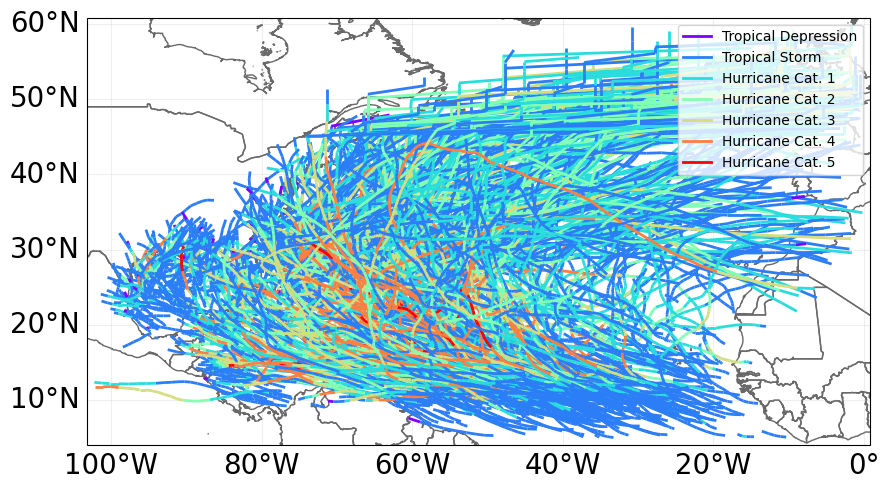

In [9]:
forecast_m[1].plot()

# Assign Random days

In [28]:
import numpy as np
import pandas as pd
from datetime import timedelta
from climada.hazard import TCTracks


def shift_tctracks_uniform_days(
    tracks: TCTracks,
    max_days: float = 30.0,
    seed: int | None = None,
    inplace: bool = False,
    return_offsets: bool = False,
):
    """
    Shift each track in a TCTracks object by an independent U(0, max_days) offset.

    Parameters
    ----------
    tracks : TCTracks
        Input CLIMADA TCTracks object.
    max_days : float
        Upper bound of uniform shift in days.
    seed : int | None
        Random seed for reproducibility.
    inplace : bool
        If True, mutate `tracks.data`; otherwise return a new TCTracks object.
    return_offsets : bool
        If True, also return the sampled offsets in days.

    Returns
    -------
    TCTracks
        Shifted TCTracks object.
    np.ndarray, optional
        Offsets in days, if return_offsets=True.
    """
    rng = np.random.default_rng(seed)
    offsets_days = rng.integers(0, int(max_days) + 1, size=len(tracks.data))

    def _shift_one(ds, days):
        time = ds["time"]

        # Fast path for normal numpy/pandas datetime64 coordinates
        if np.issubdtype(time.dtype, np.datetime64):
            delta = pd.to_timedelta(float(days), unit="D")
            return ds.assign_coords(time=time + delta)

        # Fallback for cftime/object calendars
        delta = timedelta(days=float(days))
        new_time = [t + delta for t in time.values]
        return ds.assign_coords(time=("time", new_time))

    shifted_data = [_shift_one(ds, days) for ds, days in zip(tracks.data, offsets_days)]

    if inplace:
        tracks.data = shifted_data
        out = tracks
    else:
        out = TCTracks(
            data=shifted_data,
            pool=getattr(tracks, "pool", None),
        )

    return (out, offsets_days) if return_offsets else out


In [29]:
forecast_m_corr = [shift_tctracks_uniform_days(
    forecast_m[i],
    max_days=30,
    seed=42,
    return_offsets=False,
) for i in range(len(forecast_m))]


## Compute counts

In [30]:
# Build summary year
import pandas as pd
from math import inf

SS_CAT = pd.DataFrame(
    {
        "Cat": ["TS", "C1", "C2", "C3", "C4", "C5"],
        "Wind_min": [34, 64, 83, 96, 113, 137],
        "Wind_ax": [64, 83, 96, 113, 137, inf],
    }
)
COUNTS = []
for j in range(len(forecast_m)):  # iterate over members SEAS5
    forecast_j = forecast_m[j].data
    for year in range(100):  # iterate over each year
        forecast_j_year = [
            forecast_j[i].max_sustained_wind.max().to_numpy()
            for i in range(len(forecast_j))
            if int(forecast_j[i].name.split("-")[1]) == year
        ]
        if len(forecast_j_year) > 0:
            COUNTS.append(
                [
                    len(
                        [
                            forecast_j_year[k]
                            for k in range(len(forecast_j_year))
                            if forecast_j_year[k] >= SS_CAT.iloc[i, 1]
                            # and forecast_j_year[k] < SS_CAT.iloc[i, 2]
                        ]
                    )
                    for i in range(SS_CAT.shape[0])
                ]
            )
        else:
            COUNTS.append([0] * 6)

counts_df = pd.DataFrame(COUNTS, columns=SS_CAT["Cat"])

## Plot counts

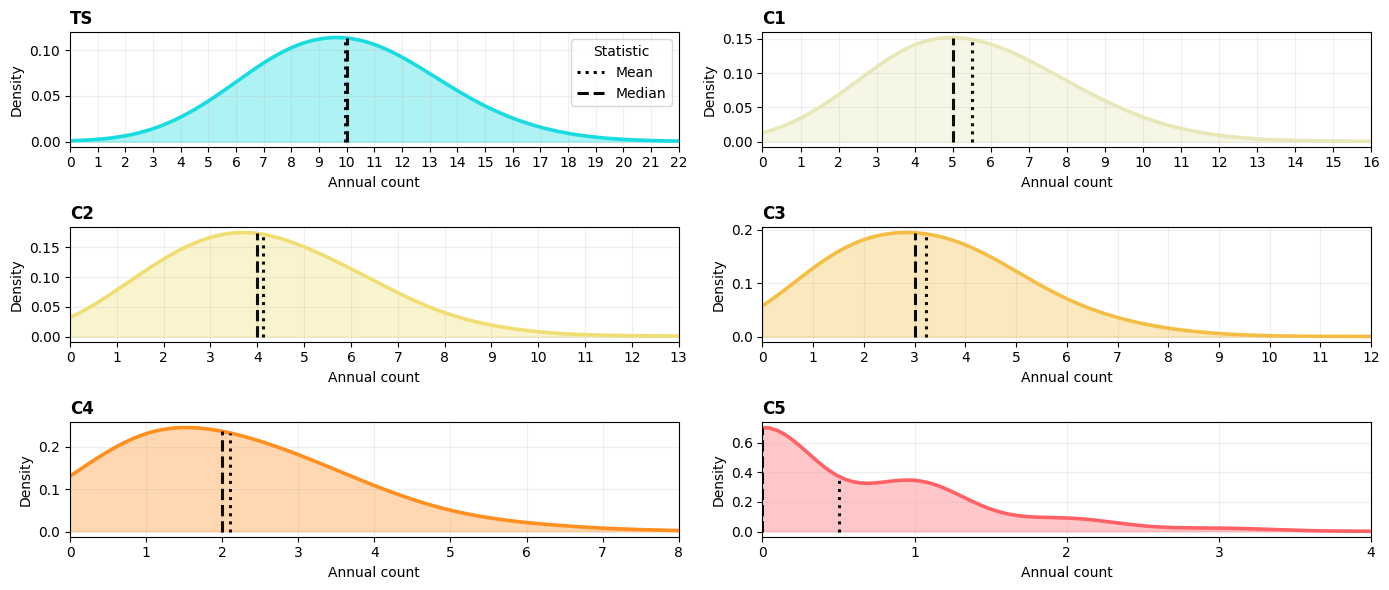

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator


def plot_storm_count_distributions(
    counts_df: pd.DataFrame,
    columns=("TS", "C1", "C2", "C3", "C4", "C5"),
    stats=("median", "mode"),
    bw_adjust=2.2,  # larger = smoother KDE
    fill=True,
    sharex=True,
):
    """
    Plot one KDE per storm category with vertical bars from y=0 up to the KDE
    at the requested summary statistics.

    Parameters
    ----------
    counts_df : pd.DataFrame
        Rows = years, columns = storm categories.
    columns : tuple/list
        Column order to plot.
    stats : tuple/list
        Supported: 'median', 'mode', 'mean'
    bw_adjust : float
        Multiplier on Scott bandwidth. Increase to smooth more for discrete counts.
    fill : bool
        Fill under each KDE.
    sharex : bool
        Share x-axis across subplots.
    """

    # Approximate Saffir-Simpson-like palette from TS to Cat 5
    colors = {
        # "TD": "#7FFFD4",
        "TS": "#18DCE0",  # tropical storm cyan
        "C1": "#E8E7B8",  # pale yellow
        "C2": "#F0DE73",  # warm yellow
        "C3": "#F4BE45",  # golden
        "C4": "#FF8F1F",  # orange
        "C5": "#FF6165",  # coral red
    }

    stat_styles = {
        "median": {"linestyle": "--", "linewidth": 2.2},
        "mode": {"linestyle": "-", "linewidth": 2.4},
        "mean": {"linestyle": ":", "linewidth": 2.2},
    }

    plot_cols = [c for c in columns if c in counts_df.columns]
    if not plot_cols:
        raise ValueError("None of the requested columns were found in counts_df.")

    n = len(plot_cols)
    fig, axes = plt.subplots(n // 2, 2, figsize=(14, n), sharex=sharex, squeeze=False)
    axes = axes.ravel()

    global_xmin = np.inf
    global_xmax = -np.inf
    kde_info = []

    # First pass: compute KDEs and x-ranges
    for col in plot_cols:
        x = counts_df[col].dropna().astype(float).to_numpy()
        if len(x) == 0:
            kde_info.append((col, None, None, None))
            continue

        xmin, xmax = x.min(), x.max()
        global_xmin = min(global_xmin, xmin)
        global_xmax = max(global_xmax, xmax)

        kde_info.append((col, x, xmin, xmax))

    if not np.isfinite(global_xmin):
        raise ValueError("All selected columns are empty.")

    xpad = max(
        1.0, 0.12 * (global_xmax - global_xmin if global_xmax > global_xmin else 5)
    )
    xs = np.linspace(max(0, global_xmin - xpad), global_xmax + xpad, 500)
    # Legend handles for summary stats
    legend_handles = []
    for s in stats:
        if s in stat_styles:
            legend_handles.append(
                Line2D(
                    [0],
                    [0],
                    color="black",
                    linestyle=stat_styles[s]["linestyle"],
                    linewidth=stat_styles[s]["linewidth"],
                    label=s.capitalize(),
                )
            )

    for ax, (col, x, xmin, xmax) in zip(axes, kde_info):
        if x is None:
            ax.set_visible(False)
            continue

        color = colors.get(col, None)

        # Constant series: no KDE possible
        if np.allclose(x, x[0]):
            x0 = x[0]
            ax.vlines(x0, 0, 1.0, color=color, linewidth=2.5)
            ax.set_ylim(0, 1.05)
            ax.set_title(col, fontsize=12, loc="left", fontweight="bold")
            ax.set_ylabel("Density")
            ax.grid(alpha=0.2)
            continue

        # Stronger smoothing to reduce artificial multimodality for discrete counts
        kde = gaussian_kde(x, bw_method=lambda s: s.scotts_factor() * bw_adjust)
        ys = kde(xs)

        ax.plot(xs, ys, color=color, linewidth=2.6)
        if fill:
            ax.fill_between(xs, 0, ys, color=color, alpha=0.35)

        # Summary statistic locations
        stat_x = {}
        if "median" in stats:
            stat_x["median"] = np.median(x)
        if "mean" in stats:
            stat_x["mean"] = x.mean()
        if "mode" in stats:
            # mode of the smoothed KDE
            stat_x["mode"] = xs[np.argmax(ys)]

        # Draw vertical bars up to density height
        for stat_name, x0 in stat_x.items():
            y0 = float(kde([x0])[0])
            ax.vlines(x0, 0, y0, color="black", alpha=0.95, **stat_styles[stat_name])

        ax.set_title(col, fontsize=12, loc="left", fontweight="bold")
        ax.set_ylabel("Density")
        ax.grid(alpha=0.2)
        ax.set_xlabel("Annual count")
        ax.tick_params(axis="x", labelbottom=True)
        ax.xaxis.set_major_locator(MultipleLocator(1))
        ax.set_xlim((0, x.max()))

    if legend_handles:
        axes[0].legend(
            handles=legend_handles, loc="upper right", frameon=True, title="Statistic"
        )

    # fig.suptitle(
    #     "Distribution of yearly storm counts by category", y=0.995, fontsize=14
    # )
    fig.tight_layout()
    return fig, axes


fig, axes = plot_storm_count_distributions(
    counts_df,
    columns=["TS", "C1", "C2", "C3", "C4", "C5"],
    stats=("mean", "median"),
    bw_adjust=2.2,
    fill=True,
    sharex=False,
)
plt.show()


# Evaluation against CSU/IBTrACS

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))
from POST_PROCESSING.utils.climada_utils import from_simulations_storm_mod

# forecast_m = [
#     from_simulations_storm_mod(
#         f"/home/mbaldacchino/data/SIENA-IH-STORM_1980_2025_VF/SIENA-IH-STORM/STORM_DATA_IBTRACS_NA_FORECAST_m{m}_100_YEARS_{i}.txt"
#     )
#     for i in range(2)
#     for m in range(10)
# ]

# several years:

storm_dir = "/home/mbaldacchino/data/DATA_STORM_and_FORECAST/SIENA_FORECAST/"
forecast_multi = [
    [
        from_simulations_storm_mod(
            storm_dir
            + f"Forecast_04_{year}/STORM_DATA_IBTRACS_NA_FORECAST_m{m}_100_YEARS_0.txt"
        )
        for m in range(51)
    ]
    for year in range(2018, 2026)
]


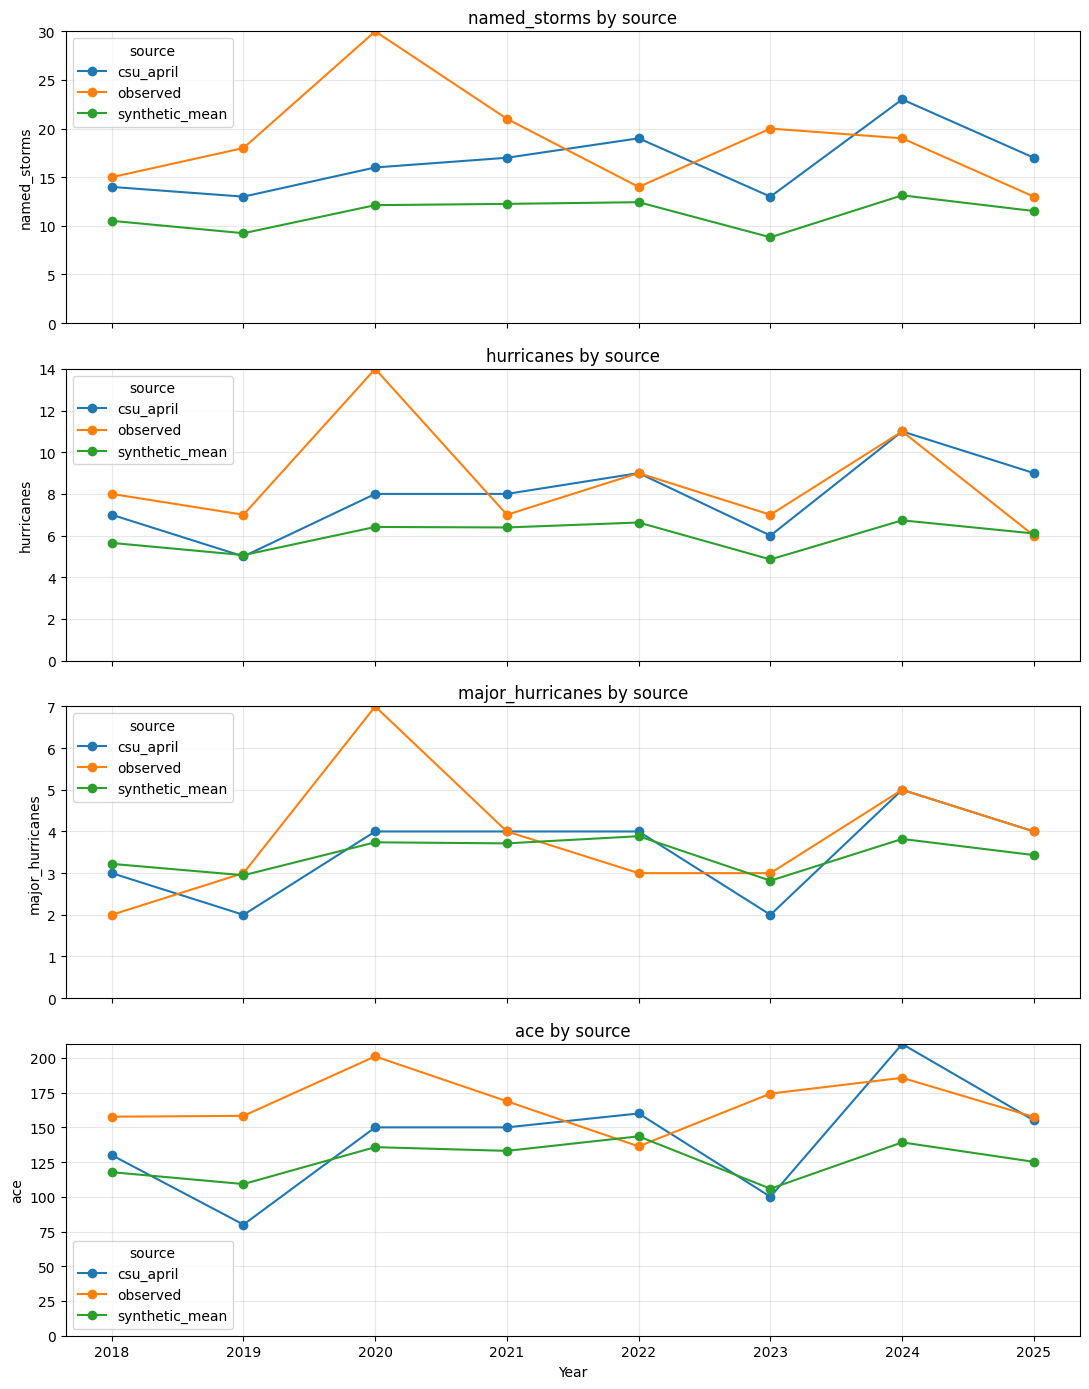

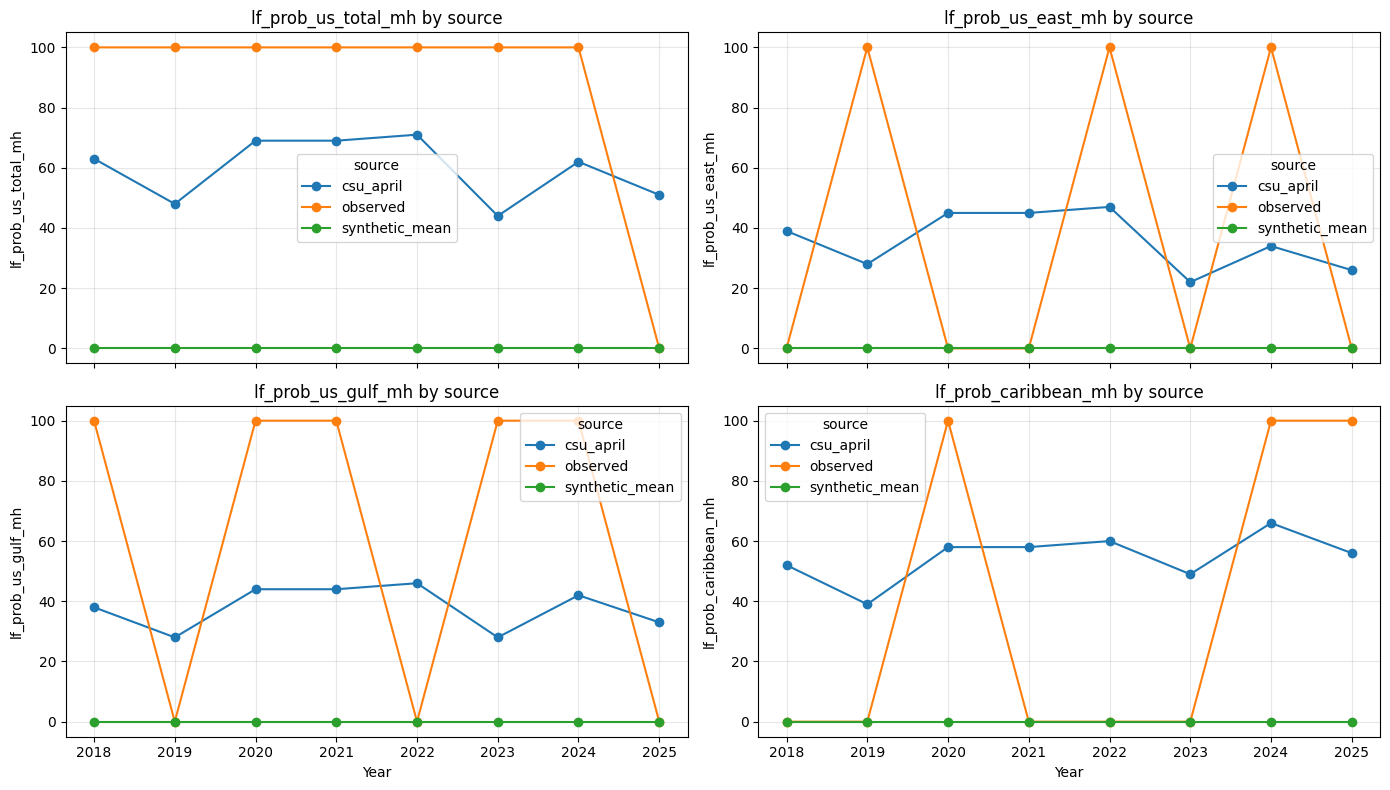

In [ ]:
import matplotlib.pyplot as plt
from FORECAST.tc_forecast_verification import (
    compare_seasons,
    plot_metric_comparison,
    plot_distribution_per_year,
)

# --- 1. Your synthetic forecasts ------------------------------------------
# synthetic[year] is a list[TCTracks], one TCTracks per stochastic season
# (i.e. the ensemble members of your April-issued forecast for that year).
# Example shape:
#   synthetic = {
#       2017: [tt_member_1, tt_member_2, ..., tt_member_N],
#       2018: [...],
#       ...
#       2025: [...],
#   }
synthetic = {
    2018: forecast_multi[0],
    2019: forecast_multi[1],
    2020:forecast_multi[2],
    2021:forecast_multi[3],
    2022:forecast_multi[4],
    2023:forecast_multi[5],
    2024:forecast_multi[6],
    2025: forecast_multi[7],
}  # <- whatever returns the dict above

years = sorted(synthetic.keys())


# Get both the summary df and the per-season distributions
df, seasons_by_year = compare_seasons(
    synthetic_members_by_year=synthetic,
    years=range(2018,2026),
    ace_method="scaled",
    sim_year_attr="sid",
    expected_sim_years_per_member=100,
    n_workers=10,
    return_seasons=True,
)

# --- Multi-panel comparison: counts and ACE ---
fig, axes = plt.subplots(4, 1, figsize=(11, 14), sharex=True)

for ax, metric in zip(axes, ["named_storms", "hurricanes", "major_hurricanes", "ace"]):
    plot_metric_comparison(df, metric, ax=ax)
    ax.set_ylim(0,df[metric].max())
fig.tight_layout()
fig.savefig("metrics_by_year.png", dpi=150)

# --- Landfall probability comparison (one panel per region, MH only) ---
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, metric in zip(
    axes.flat,
    [
        "lf_prob_us_total_mh",
        "lf_prob_us_east_mh",
        "lf_prob_us_gulf_mh",
        "lf_prob_caribbean_mh",
    ],
):
    plot_metric_comparison(df, metric, ax=ax)
fig.tight_layout()
fig.savefig("landfall_probs_by_year.png", dpi=150)




# --- Violin plot: synthetic 5100-season distribution + observed/CSU markers ---
# This is the most informative plot for your use case — it shows the FULL
# uncertainty of your model alongside the single-number CSU forecast.
for metric in ["named_storms", "hurricanes", "major_hurricanes", "ace"]:
    fig, ax = plt.subplots(figsize=(11, 5))
    plot_distribution_per_year(seasons_by_year, metric, df_summary=df, ax=ax)
    fig.tight_layout()
    fig.savefig(f"distribution_{metric}.png", dpi=150)
    plt.close(fig)

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
from POST_PROCESSING.utils.climada_utils import from_simulations_storm_mod
from FORECAST.tc_forecast_verification_bis import (
    compare_seasons,
    plot_metric_comparison,
    plot_distribution_per_year,
)

# --- 1. Load synthetic forecasts ------------------------------------------
storm_dir = "/home/mbaldacchino/data/DATA_STORM_and_FORECAST/SIENA_FORECAST/"
forecast_multi = [
    [
        from_simulations_storm_mod(
            storm_dir
            + f"Forecast_04_{year}/STORM_DATA_IBTRACS_NA_FORECAST_m{m}_100_YEARS_0.txt"
        )
        for m in range(51)
    ]
    for year in range(2018, 2026)
]

synthetic = {year: forecast_multi[i] for i, year in enumerate(range(2018, 2026))}
years = sorted(synthetic.keys())

# --- 2. Run the comparison ------------------------------------------------
# `include_climatology=True` is the default, so 1991-2020 IBTrACS climatology
# is computed automatically (one extra IBTrACS load on the first call).
# `tsr_april_forecasts` defaults to TSR_APRIL_FORECASTS, also automatic.
df, seasons_by_year = compare_seasons(
    synthetic_members_by_year=synthetic,
    years=range(2018, 2026),
    ace_method="scaled",
    sim_year_attr="sid",
    expected_sim_years_per_member=100,
    n_workers=10,
    return_seasons=True,
    include_climatology=True,  # default; explicit for clarity
    climatology_years=range(1991, 2021),  # default; explicit for clarity
)

# Save the full table for the record
df.to_csv("comparison_table.csv")
print(df.to_string(float_format=lambda x: f"{x:.2f}"))

# --- 3. Multi-panel comparison: counts and ACE ----------------------------
fig, axes = plt.subplots(4, 1, figsize=(11, 14), sharex=True)
for ax, metric in zip(axes, ["named_storms", "hurricanes", "major_hurricanes", "ace"]):
    plot_metric_comparison(df, metric, ax=ax)
    # Set y-floor to 0; let max auto-determine so climatology line stays visible
    ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig("metrics_by_year.png", dpi=150)
plt.close(fig)

# --- 4. Landfall probability comparison (CSU-only forecast schema) --------
# Note: TSR doesn't issue probabilities (only US-LF counts), so its line
# won't appear in these panels. CSU + your synthetic + observed will.
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, metric in zip(
    axes.flat,
    [
        "lf_prob_us_total_mh",
        "lf_prob_us_east_mh",
        "lf_prob_us_gulf_mh",
        "lf_prob_caribbean_mh",
    ],
):
    plot_metric_comparison(df, metric, ax=ax)
    ax.set_ylim(0, 100)  # probabilities are bounded
fig.tight_layout()
fig.savefig("landfall_probs_by_year.png", dpi=150)
plt.close(fig)

# --- 5. NEW: TSR-style US-landfall counts ---------------------------------
# TSR's bread and butter for reinsurance: actual landfall count forecasts.
# Your synthetic puts pooled-mean counts in landfall_ts/landfall_hu, which
# is the same column TSR uses, so this comparison is direct.
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, metric in zip(axes, ["landfall_ts", "landfall_hu", "us_landfall_ace"]):
    plot_metric_comparison(df, metric, ax=ax)
    ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig("us_landfall_counts.png", dpi=150)
plt.close(fig)

# --- 6. Violin: synthetic 5100-season distribution + all forecasters ------
# `plot_distribution_per_year` now overlays observed + CSU + TSR markers
# and a horizontal climatology reference line, all from df_summary.
for metric in ["named_storms", "hurricanes", "major_hurricanes", "ace"]:
    fig, ax = plt.subplots(figsize=(11, 5))
    plot_distribution_per_year(seasons_by_year, metric, df_summary=df, ax=ax)
    fig.tight_layout()
    fig.savefig(f"distribution_{metric}.png", dpi=150)
    plt.close(fig)

# --- 7. Skill summary -----------------------------------------------------
from FORECAST.tc_forecast_verification_bis import skill_summary, landfall_brier_scores

skill = skill_summary(df)
print("\nSkill summary (forecast bias, MAE, RMSE, correlation vs observed):")
print(skill.to_string(float_format=lambda x: f"{x:.2f}"))
skill.to_csv("skill_summary.csv")

print("\nBrier scores - CSU April vs observed (MH landfall):")
print(
    landfall_brier_scores(df, "csu_april").to_string(float_format=lambda x: f"{x:.3f}")
)

print("\nBrier scores - synthetic_mean vs observed (MH landfall):")
print(
    landfall_brier_scores(df, "synthetic_mean").to_string(
        float_format=lambda x: f"{x:.3f}"
    )
)


2026-05-04 09:49:10,147 - climada.hazard.tc_tracks - WARNING - 2 storm events are discarded because no valid wind/pressure values have been found: 1991187N23264, 1991241N11329.
2018
2019
2020
2021
2022
2023
2024


/home/mbaldacchino/code/SIENA-IH-STORM/FORECAST/tc_forecast_verification_bis.py:664: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out[c] = out[c].fillna(False).astype(bool)
/home/mbaldacchino/code/SIENA-IH-STORM/FORECAST/tc_forecast_verification_bis.py:664: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out[c] = out[c].fillna(False).astype(bool)
/home/mbaldacchino/code/SIENA-IH-STORM/FORECAST/tc_forecast_verification_bis.py:664: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Ca

2025
                            named_storms  hurricanes  major_hurricanes    ace  landfall_ts  landfall_hu  landfall_mh  lf_prob_us_total_ts  lf_prob_us_total_hu  lf_prob_us_total_mh  lf_prob_us_east_ts  lf_prob_us_east_hu  lf_prob_us_east_mh  lf_prob_us_gulf_ts  lf_prob_us_gulf_hu  lf_prob_us_gulf_mh  lf_prob_caribbean_ts  lf_prob_caribbean_hu  lf_prob_caribbean_mh  us_landfall_ace  named_storms_p05  named_storms_p50  named_storms_p95  hurricanes_p05  hurricanes_p50  hurricanes_p95  major_hurricanes_p05  major_hurricanes_p50  major_hurricanes_p95  ace_p05  ace_p50  ace_p95  landfall_ts_p05  landfall_ts_p50  landfall_ts_p95  landfall_hu_p05  landfall_hu_p50  landfall_hu_p95  landfall_mh_p05  landfall_mh_p50  landfall_mh_p95
year source                                                                                                                                                                                                                                                             

In [4]:
import xarray as xr

ib = xr.open_dataset(
    "/home/mbaldacchino/data/SIENA-IH-STORM_1980_2021/SIENA-IH-STORM/IBTrACS.1980_2021v04r01.nc",
    decode_times=False,
)
df = ib.to_dataframe()
# Atlantic storms only
na = df[(df["basin"] == b"NA")]
# Per-storm peak wind in m/s (from kt)
peaks = na.groupby("sid")["wmo_wind"].max() * 0.5144
# Count by category
ts_total = (peaks >= 17.49).sum()  # ≥ 34 kt 1-min, no STORM 0.88 conversion
above_threshold = (peaks * 0.88 >= 15.84).sum()  # what your training keeps
print(f"Total IBTrACS NS (≥34 kt 1-min): {ts_total}")
print(f"Retained by training filter:     {above_threshold}")
print(f"Difference: {ts_total - above_threshold}")


Total IBTrACS NS (≥34 kt 1-min): 564
Retained by training filter:     564
Difference: 0


In [7]:
import numpy as np

phase_rates = np.load(
    "/home/mbaldacchino/data/SIENA-IH-STORM_1980_2021/SIENA-IH-STORM/POISSON_GENESIS_PARAMETERS_PHASE.npy",
    allow_pickle=True,
).item()
pooled = np.loadtxt(
    "/home/mbaldacchino/data/SIENA-IH-STORM_1980_2021/SIENA-IH-STORM/POISSON_GENESIS_PARAMETERS.txt"
)
print(f"Pooled NA rate: {pooled[1]}")
print(
    f"Phase rates NA: LN={phase_rates[1][0]}, NEU={phase_rates[1][1]}, EN={phase_rates[1][2]}"
)


Pooled NA rate: 12.2
Phase rates NA: LN=15.0, NEU=12.4, EN=8.9


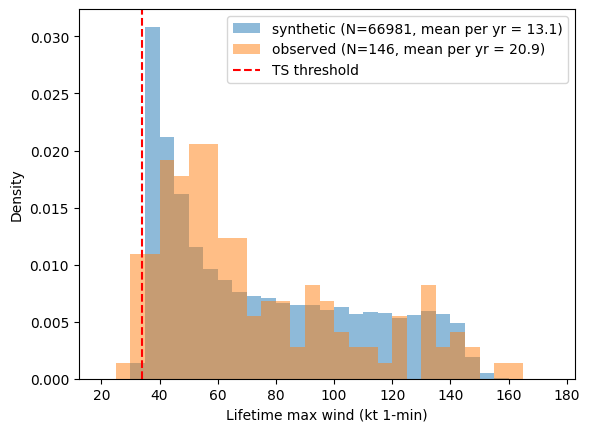

In [9]:
import numpy as np
from FORECAST.tc_forecast_verification import _extract_track_features, load_ibtracs_na
from CODE.fast_land_mask import FastLandMask

mask = FastLandMask()

# Your synthetic
syn_vmax = []
for member in synthetic[2024]:  # 51 members
    for tr in member.data:
        vmax = float(np.nanmax(tr.max_sustained_wind.values))
        syn_vmax.append(vmax)
syn_vmax = np.array(syn_vmax)

# IBTrACS 2018-2024
ib = load_ibtracs_na(range(2018, 2025))
obs_vmax = np.array([float(np.nanmax(tr.max_sustained_wind.values)) for tr in ib.data])

import matplotlib.pyplot as plt

fig, ax = plt.subplots()
bins = np.arange(20, 180, 5)
ax.hist(
    syn_vmax,
    bins=bins,
    alpha=0.5,
    label=f"synthetic (N={len(syn_vmax)}, mean per yr = {len(syn_vmax) / (51 * 100):.1f})",
    density=True,
)
ax.hist(
    obs_vmax,
    bins=bins,
    alpha=0.5,
    label=f"observed (N={len(obs_vmax)}, mean per yr = {len(obs_vmax) / 7:.1f})",
    density=True,
)
ax.axvline(34, color="red", linestyle="--", label="TS threshold")
ax.legend()
ax.set_xlabel("Lifetime max wind (kt 1-min)")
ax.set_ylabel("Density")
fig.savefig("vmax_distribution.png")


In [12]:
"""
Test 1: Verify ENSO phase assignment by month.

Convention:
  - ONI is the 3-month running mean of Niño 3.4 SST anomaly.
  - Each ONI value is centred on its middle month
    (e.g., the "ASO" value, which is mean(Aug+Sep+Oct), is indexed to September).
  - Phase classification uses the threshold from input.dat (default 0.5):
      EN  if ONI >= +0.5 for 5 consecutive overlapping seasons
      LN  if ONI <= -0.5 for 5 consecutive overlapping seasons
      NEU otherwise

  However the SIMPLE per-month threshold-only definition (what your code uses)
  is just: phase = sign(ONI) * 1{|ONI| >= threshold}. NOAA's official phase
  uses the consecutive-seasons rule which is stricter; expect occasional
  disagreements on month-by-month boundaries.

What this test does:
  (a) Loads your climate_index.csv.
  (b) Compares your phase assignment for ~10 well-known year-months against
      NOAA's published ONI table.
  (c) Prints the table of (year, month, your_ONI, your_phase, expected_phase).
  (d) Flags any disagreements.
"""

import pandas as pd
import numpy as np
from CODE.siena_utils import load_climate_index_table

# NOAA ONI values for selected month-centres (3-month centred mean of Niño 3.4).
# Source: https://origin.cpc.ncep.noaa.gov/products/analysis_monitoring/ensostuff/ONI_v5.php
# Format: (year, month_centre, expected_ONI, expected_phase_simple_threshold)
# These are the ONI values where, e.g., (2020, 9) means the ASO 2020 ONI value.
EXPECTED = [
    # year, month, ONI,  phase   (using simple |ONI| >= 0.5 rule)
    (2020, 1, 0.5, "EN"),  # DJF 19/20: weak EN (last gasp)
    (2020, 9, -0.9, "LN"),  # ASO 2020: La Nina developing
    (2020, 12, -1.2, "LN"),  # NDJ 20/21: La Nina peak
    (2021, 3, -0.8, "LN"),  # FMA 2021: La Nina decay
    (2021, 9, -0.7, "LN"),  # ASO 2021: La Nina re-emerged
    (2022, 3, -1.0, "LN"),  # FMA 2022: triple-dip La Nina
    (2022, 9, -1.0, "LN"),  # ASO 2022
    (2023, 6, 0.5, "EN"),  # MJJ 2023: El Nino developing
    (2023, 9, 1.6, "EN"),  # ASO 2023: strong EN
    (2024, 9, -0.2, "NEU"),  # ASO 2024: weak La Nina developing but below threshold
    (2024, 12, -0.5, "LN"),  # NDJ 24/25
]

THRESHOLD = 0.5  # matches input.dat


def main():
    df = load_climate_index_table(
        "/home/mbaldacchino/data/SIENA-IH-STORM_1980_2025_VF/SIENA-IH-STORM/climate_index.csv"
    )
    print(f"Loaded {len(df)} rows. Columns: {list(df.columns)}")
    print(f"Year range: {df['year'].min()}-{df['year'].max()}")
    print()

    # Build a fast lookup: (year, month) -> (oni_value, phase_string)
    lookup = {
        (int(r["year"]), int(r["month"])): (
            float(r["climate_index"]),
            str(r["phase"]).strip().upper(),
        )
        for _, r in df.iterrows()
    }

    fails = 0
    print(
        f"{'year':>5} {'mo':>3}  {'expected_ONI':>12} {'your_ONI':>9} "
        f"{'exp_phase':>9} {'your_phase':>10}  {'match':>6}"
    )
    print("-" * 65)
    for yr, mo, exp_oni, exp_phase in EXPECTED:
        got = lookup.get((yr, mo))
        if got is None:
            print(
                f"{yr:>5} {mo:>3}  {exp_oni:>12.2f}    MISSING       {exp_phase:>9} "
                f"  -          MISS"
            )
            fails += 1
            continue
        got_oni, got_phase = got
        # Compare: ONI within 0.1, phase exact match
        oni_ok = abs(got_oni - exp_oni) <= 0.15
        phase_ok = got_phase == exp_phase
        match = "OK" if (oni_ok and phase_ok) else ("FAIL" if not oni_ok else "PHASE")
        if match != "OK":
            fails += 1
        print(
            f"{yr:>5} {mo:>3}  {exp_oni:>12.2f} {got_oni:>9.2f} "
            f"{exp_phase:>9} {got_phase:>10}  {match:>6}"
        )

    print()
    print(f"Result: {len(EXPECTED) - fails}/{len(EXPECTED)} pass")
    print()

    # Sanity check #2: the simple-threshold phase derived from your ONI value
    # should match the phase string you stored, for every row.
    print("Cross-check: phase string matches |ONI| >= 0.5 rule across full table?")
    df2 = df.copy()
    df2["expected_phase"] = np.where(
        df2["climate_index"].astype(float) >= THRESHOLD,
        "EN",
        np.where(df2["climate_index"].astype(float) <= -THRESHOLD, "LN", "NEU"),
    )
    df2["stored_phase"] = df2["phase"].astype(str).str.strip().str.upper()
    mismatch = df2[df2["expected_phase"] != df2["stored_phase"]]
    print(f"  {len(mismatch)}/{len(df2)} rows where stored phase != threshold rule")
    if len(mismatch) > 0 and len(mismatch) < 30:
        print(
            mismatch[
                ["year", "month", "climate_index", "stored_phase", "expected_phase"]
            ].to_string()
        )
    elif len(mismatch) >= 30:
        print("  (showing first 10)")
        print(
            mismatch.head(10)[
                ["year", "month", "climate_index", "stored_phase", "expected_phase"]
            ].to_string()
        )
        print("  NOTE: NOAA uses a 5-consecutive-seasons rule, not threshold-only.")
        print("  Your stored phase may follow NOAA's stricter rule.")
        print("  In that case, this 'mismatch' is expected and NOT a bug.")


if __name__ == "__main__":
    main()


Loaded 552 rows. Columns: ['Unnamed: 0', 'year', 'month', 'climate_index', 'phase']
Year range: 1980-2025

 year  mo  expected_ONI  your_ONI exp_phase your_phase   match
-----------------------------------------------------------------
 2020   1          0.50      0.64        EN         EN      OK
 2020   9         -0.90     -0.85        LN         LN      OK
 2020  12         -1.20     -1.08        LN         LN      OK
 2021   3         -0.80     -0.71        LN         LN      OK
 2021   9         -0.70     -0.63        LN         LN      OK
 2022   3         -1.00     -0.86        LN         LN      OK
 2022   9         -1.00     -0.97        LN         LN      OK
 2023   6          0.50      0.84        EN         EN    FAIL
 2023   9          1.60      1.60        EN         EN      OK
 2024   9         -0.20     -0.17       NEU        NEU      OK
 2024  12         -0.50     -0.42        LN        NEU   PHASE

Result: 9/11 pass

Cross-check: phase string matches |ONI| >= 0.5 rule

In [19]:
"""
Test 1b: Verify the forecast's per-month phase assignment for a given year.

For an April-issued forecast of year Y, the forecast covers June-November Y.
The April forecaster knows ONI values up to roughly FMA-Y (centred March).
For later months (June-Nov), ENSO must be projected from a seasonal forecast.

This test loads a forecast_config.json (or the dict returned by your forecast
config builder) and prints the phase assigned to each active month for years
2018-2025. It then cross-checks each phase against the corresponding NOAA
ONI value for that month-centre.

Use this to verify that:
  - Your forecast IS conditioning on ENSO (not defaulting to NEU)
  - The phase assignment makes physical sense given what was knowable in April
  - The phase matches the eventual realised phase as much as possible
"""

import json
from pathlib import Path
import pandas as pd
from CODE.siena_utils import load_climate_index_table


def realized_phase(year, month, oni_lookup, threshold=0.5):
    """Return realized phase from NOAA ONI for the given month-centre."""
    val = oni_lookup.get((year, month))
    if val is None:
        return "?"
    if val >= threshold:
        return "EN"
    if val <= -threshold:
        return "LN"
    return "NEU"


def main():
    # Load the realized ONI for cross-check
    df = load_climate_index_table(
        "/home/mbaldacchino/data/SIENA-IH-STORM_1980_2025_VF/SIENA-IH-STORM/climate_index.csv"
    )
    oni_lookup = {
        (int(r["year"]), int(r["month"])): float(r["climate_index"])
        for _, r in df.iterrows()
    }

    # Path to your forecast configs - adjust as needed
    config_dir = Path(
        "/home/mbaldacchino/data/SIENA-IH-STORM_1980_2021/SIENA-IH-STORM/forecast_configs"
    )  # or wherever they are
    if not config_dir.exists():
        # Try alternative locations
        for cand in ["FORECAST/configs", "forecast_configs", "."]:
            if Path(cand).exists():
                # look for forecast JSONs
                jsons = list(Path(cand).glob("forecast_config_*.json"))
                if jsons:
                    config_dir = Path(cand)
                    break
        else:
            print("Could not find forecast config files. Adjust config_dir manually.")
            return

    print(
        f"{'Year':>5}  {'Month':>5}  {'Forecast phase':>14}  "
        f"{'Realized ONI':>13}  {'Realized phase':>14}  {'Match':>5}"
    )
    print("-" * 75)

    matches = 0
    total = 0
    for year in range(2025, 2026):
        # Adjust filename pattern to your actual layout
        cfg_path = config_dir / f"config_m10.json"
        if not cfg_path.exists():
            cfg_path = config_dir / f"Forecast_04.json"
        if not cfg_path.exists():
            print(f"  {year}: config file not found, skipping")
            continue

        with open(cfg_path) as f:
            cfg = json.load(f)

        # Active months for NA
        active_months = [6, 7, 8, 9, 10, 11]
        for m in active_months:
            entry = cfg["months"].get(str(m))
            fcst_phase = (entry or {}).get("phase", "MISSING")

            real_oni = oni_lookup.get((year, m))
            real_phase = realized_phase(year, m, oni_lookup)
            match = "OK" if fcst_phase == real_phase else "diff"
            if real_phase != "?":
                total += 1
                if fcst_phase == real_phase:
                    matches += 1

            real_oni_str = (
                f"{real_oni:>13.2f}" if real_oni is not None else "          n/a"
            )
            print(
                f"{year:>5}  {m:>5}  {fcst_phase:>14}  {real_oni_str}  "
                f"{real_phase:>14}  {match:>5}"
            )
        print()

    if total > 0:
        print(
            f"Overall realized-phase match: {matches}/{total} = "
            f"{matches / total * 100:.0f}%"
        )
        print("(Some mismatch is expected for late-season months — they were")
        print(" forecast 4-7 months ahead. Match should be ~70-100% for early")
        print(" months and degrade for later ones.)")


if __name__ == "__main__":
    main()


 Year  Month  Forecast phase   Realized ONI  Realized phase  Match
---------------------------------------------------------------------------
 2025      6             NEU          -0.04             NEU     OK
 2025      7              EN          -0.14             NEU   diff
 2025      8              EN          -0.28             NEU   diff
 2025      9              EN          -0.40             NEU   diff
 2025     10              EN          -0.51              LN   diff
 2025     11              EN          -0.55              LN   diff

Overall realized-phase match: 1/6 = 17%
(Some mismatch is expected for late-season months — they were
 forecast 4-7 months ahead. Match should be ~70-100% for early
 months and degrade for later ones.)


In [20]:
"""
Test 2: Diagnose Genwind (initial wind sampling distribution).

What this tests:
  (a) Distribution shape: histogram of Genwind values per basin per month,
      compared to observed first-TS-onset winds in IBTrACS.
  (b) Lower-tail concentration: what fraction of Genwind samples are within
      X kt of the TS threshold? These are the "decay-prone" storms.
  (c) Empirical attrition: simulate one timestep of dp1 sampling from each
      Genwind value and count what fraction would drop back below TS.

Why this matters:
  The synthetic histogram you produced shows ~25% of generated storms decay
  before crossing TS threshold. Genwind is the upstream culprit if its
  distribution has too much mass near the threshold. If most Genwind values
  are >= 40 kt 1-min, the attrition is downstream (dp1 sampling, MPI cap)
  and Genwind itself is fine.
"""

import os
import numpy as np
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt


# 10-min m/s -> 1-min kt conversion (matches from_simulations_storm_mod)
def ms_10min_to_kt_1min(v):
    return np.asarray(v) * 1.94384 / 0.88


def main():
    # === (a) Load Genwind ===
    path = "/home/mbaldacchino/data/SIENA-IH-STORM_1980_2025_VF/SIENA-IH-STORM/GENESIS_WIND.npy"  # adjust if you run from another dir
    if not os.path.exists(path):
        print(f"GENESIS_WIND.npy not found at {path}. Adjust path.")
        return
    gw = np.load(path, allow_pickle=True).item()

    # NA basin (idx=1)
    idx = 1
    basin_name = "NA"

    print(f"=== Genwind diagnostic for basin {basin_name} (idx={idx}) ===\n")

    # Pool across all months
    all_winds_ms = []
    for month, vals in gw[idx].items():
        all_winds_ms.extend(vals)
    all_winds_ms = np.asarray([v for v in all_winds_ms if np.isfinite(v)])
    all_winds_kt = ms_10min_to_kt_1min(all_winds_ms)

    print(f"N = {len(all_winds_ms)} initial-wind samples in training")
    print(
        f"In 10-min m/s:  mean={all_winds_ms.mean():.2f}  "
        f"median={np.median(all_winds_ms):.2f}  "
        f"std={all_winds_ms.std():.2f}"
    )
    print(
        f"In 1-min kt:    mean={all_winds_kt.mean():.2f}  "
        f"median={np.median(all_winds_kt):.2f}  "
        f"std={all_winds_kt.std():.2f}"
    )
    print()

    # === (b) Lower-tail concentration ===
    print("Lower-tail concentration (fraction of Genwind samples in 1-min kt):")
    for upper in [34, 36, 40, 45, 50]:
        frac = np.mean(all_winds_kt < upper) * 100
        print(
            f"  < {upper} kt:  {frac:5.1f}%  ({int(np.sum(all_winds_kt < upper))} samples)"
        )
    print()

    # === (c) Empirical attrition simulation ===
    # Load dp0 distribution (initial pressure tendency) - this is what samples dp1 from in sim
    print("Empirical attrition test: simulate one timestep of decay")
    print("from each Genwind sample and count storms that drop below 34 kt:")

    # Simple model: sample dp1 ~ N(0, std_typical), compute new pressure, convert to wind
    # using inverse Holland approx: v ~ sqrt(Penv - p) * coef.
    # Here we approximate as: dV1 ~ N(0, sigma_V) where sigma_V = 5 kt over 3h.
    # That's a conservative estimate for first-step wind change.
    rng = np.random.default_rng(42)
    n_trials = 100
    survival_count = 0
    total_count = 0
    for w in all_winds_kt:
        for _ in range(n_trials):
            # Sample first-step wind change ~ N(0, 5 kt) - rough proxy
            dv = rng.normal(0, 5)
            new_w = w + dv
            total_count += 1
            if new_w >= 34.0:
                survival_count += 1
    survival_rate = survival_count / total_count
    print(f"  {survival_rate * 100:.1f}% survive to ≥ 34 kt after one 3h step")
    print(f"  {(1 - survival_rate) * 100:.1f}% attrition (rough estimate)")
    print()
    print("  NOTE: this is a SIMPLIFIED proxy. Real attrition depends on dp1")
    print("  distribution, MPI cap, environmental pressure, and recovery over")
    print("  subsequent steps. Real attrition will be higher than this lower-bound.")
    print()

    # === (d) Plot the distribution ===
    fig, ax = plt.subplots(figsize=(10, 5))
    bins = np.arange(20, 100, 2)
    ax.hist(
        all_winds_kt,
        bins=bins,
        alpha=0.7,
        label=f"Genwind {basin_name} (n={len(all_winds_kt)})",
    )
    ax.axvline(
        34, color="red", linestyle="--", linewidth=2, label="TS threshold (34 kt)"
    )
    ax.axvline(40, color="orange", linestyle=":", linewidth=1.5, label="40 kt")
    ax.set_xlabel("Initial wind at first-TS-onset (kt 1-min)")
    ax.set_ylabel("Count")
    ax.set_title(
        f"Genwind distribution - basin {basin_name}\n"
        f"mean={all_winds_kt.mean():.1f} kt, median={np.median(all_winds_kt):.1f} kt"
    )
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig("genwind_distribution.png", dpi=120)
    print("Saved genwind_distribution.png")


if __name__ == "__main__":
    main()


=== Genwind diagnostic for basin NA (idx=1) ===

N = 579 initial-wind samples in training
In 10-min m/s:  mean=16.31  median=15.84  std=1.19
In 1-min kt:    mean=36.04  median=35.00  std=2.62

Lower-tail concentration (fraction of Genwind samples in 1-min kt):
  < 34 kt:    0.0%  (0 samples)
  < 36 kt:   84.3%  (488 samples)
  < 40 kt:   95.5%  (553 samples)
  < 45 kt:   99.5%  (576 samples)
  < 50 kt:  100.0%  (579 samples)

Empirical attrition test: simulate one timestep of decay
from each Genwind sample and count storms that drop below 34 kt:
  63.1% survive to ≥ 34 kt after one 3h step
  36.9% attrition (rough estimate)

  NOTE: this is a SIMPLIFIED proxy. Real attrition depends on dp1
  distribution, MPI cap, environmental pressure, and recovery over
  subsequent steps. Real attrition will be higher than this lower-bound.

Saved genwind_distribution.png


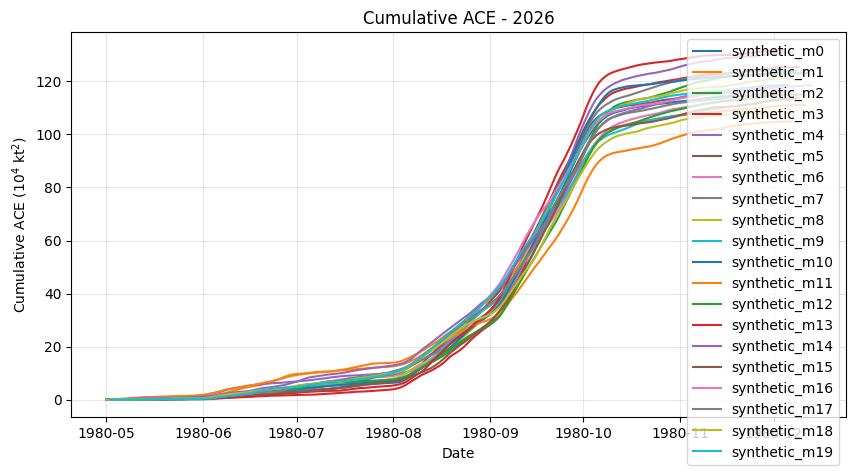

In [36]:
synthetic = {2026: forecast_m_corr}
curves = {}
target_year = 2026
for i, member in enumerate(synthetic[target_year][:200]):  # first 5 members
    curves[f"synthetic_m{i}"] = ace_curve(member, method="scaled")/100
fig, ax = plt.subplots(figsize=(10, 5))
plot_ace_curves(curves, ax=ax, title=f"Cumulative ACE - {target_year}")
fig.savefig(f"ace_curve_{target_year}.png", dpi=150)

In [41]:
curves

{'synthetic_m0': 1980-05-02      0.008544
 1980-05-03      0.037005
 1980-05-04      0.078521
 1980-05-05      0.142818
 1980-05-06      0.259310
                  ...    
 1980-12-06    115.246439
 1980-12-07    115.283167
 1980-12-08    115.322226
 1980-12-09    115.356607
 1980-12-10    115.357714
 Freq: D, Length: 223, dtype: float64,
 'synthetic_m1': 1980-05-02      0.005984
 1980-05-03      0.005984
 1980-05-04      0.012866
 1980-05-05      0.031608
 1980-05-06      0.050899
                  ...    
 1980-12-03    104.865106
 1980-12-04    104.877101
 1980-12-05    104.885696
 1980-12-06    104.894650
 1980-12-07    104.902228
 Freq: D, Length: 220, dtype: float64,
 'synthetic_m2': 1980-05-01      0.012409
 1980-05-02      0.020027
 1980-05-03      0.033045
 1980-05-04      0.033045
 1980-05-05      0.039345
                  ...    
 1980-12-03    123.112504
 1980-12-04    123.239930
 1980-12-05    123.330736
 1980-12-06    123.371446
 1980-12-07    123.373278
 Freq: D, Length

In [34]:
import pandas as pd
import matplotlib.pyplot as plt


def plot_member_average(
    members: dict,
    target_year: int | None = None,
    title: str = "Mean curve with interquartile range",
    q_low = 0.25,
    q_high = 0.75,
):
    """
    members: dict[str, pd.Series]
        Example: {"synthetic_m0": series0, "synthetic_m1": series1, ...}

    target_year:
        If None, use the original dates.
        If an int, replace the x-axis year with that year, e.g. 2026.
    """

    # Combine all member Series into one DataFrame
    df = pd.concat(members, axis=1)

    # Ensure chronological order
    df = df.sort_index()

    # Statistics across members, day by day
    mean_curve = df.mean(axis=1, skipna=True)
    qlow = df.quantile(q_low, axis=1, interpolation="linear")
    qhigh = df.quantile(q_high, axis=1, interpolation="linear")

    # Optional: change display year on x-axis
    x = mean_curve.index

    if target_year is not None:
        new_dates = []
        keep = []

        for d in x:
            try:
                new_dates.append(d.replace(year=target_year))
                keep.append(True)
            except ValueError:
                # Handles Feb 29 if target_year is not leap year
                new_dates.append(pd.NaT)
                keep.append(False)

        keep = pd.Series(keep, index=x)
        x = pd.DatetimeIndex(new_dates)[keep.values]

        mean_curve = mean_curve.loc[keep.index[keep]]
        qlow = qlow.loc[keep.index[keep]]
        qlow = qlow.loc[keep.index[keep]]

    # Plot
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(x, mean_curve.to_numpy(), label="Mean")
    ax.fill_between(
        x,
        qlow.to_numpy(),
        qhigh.to_numpy(),
        alpha=0.3,
        label=f"{round(q_low*100,0)}-{round(q_high*100,0)} percentile",
    )

    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel("Value (kt²)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    fig.autofmt_xdate()
    plt.show()

    return mean_curve, qlow, qhigh


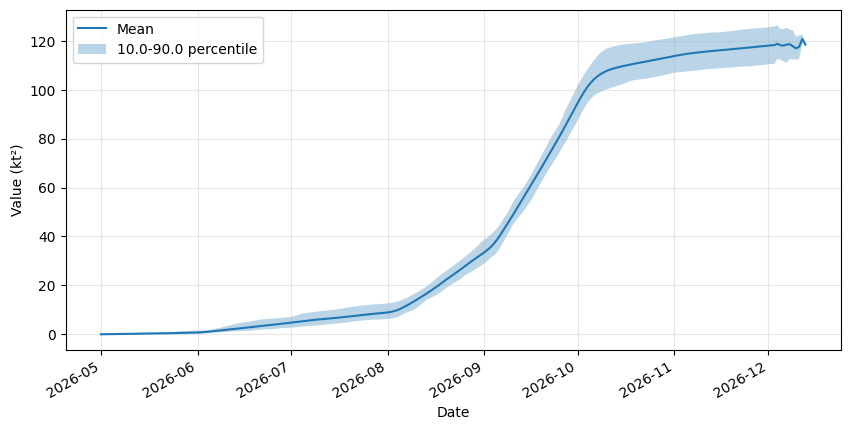

In [37]:
mean_curve, q25, q75 = plot_member_average(curves, target_year=2026, q_low = 0.1, q_high = 0.9, title="")


# Reorganize climatology

In [7]:
tst

<xarray.Dataset> Size: 1GB
Dimensions:                  (number: 51, forecast_reference_time: 27,
                              forecastMonth: 6, latitude: 120, longitude: 360)
Coordinates:
  * number                   (number) int64 408B 0 1 2 3 4 5 ... 46 47 48 49 50
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 216B 20...
  * forecastMonth            (forecastMonth) int64 48B 1 2 3 4 5 6
  * latitude                 (latitude) float64 960B 59.5 58.5 ... -58.5 -59.5
  * longitude                (longitude) float64 3kB -179.5 -178.5 ... 179.5
Data variables:
    msla                     (number, forecast_reference_time, forecastMonth, latitude, longitude) float32 1GB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-04-23T09:19 GRIB to CDM+CF via cfgrib-0.9.1...

In [6]:
tst.forecast_reference_time

<xarray.DataArray 'forecast_reference_time' (forecast_reference_time: 27)> Size: 216B
array(['2017-04-01T00:00:00.000000000', '2017-05-01T00:00:00.000000000',
       '2017-06-01T00:00:00.000000000', '2018-04-01T00:00:00.000000000',
       '2018-05-01T00:00:00.000000000', '2018-06-01T00:00:00.000000000',
       '2019-04-01T00:00:00.000000000', '2019-05-01T00:00:00.000000000',
       '2019-06-01T00:00:00.000000000', '2020-04-01T00:00:00.000000000',
       '2020-05-01T00:00:00.000000000', '2020-06-01T00:00:00.000000000',
       '2021-04-01T00:00:00.000000000', '2021-05-01T00:00:00.000000000',
       '2021-06-01T00:00:00.000000000', '2022-04-01T00:00:00.000000000',
       '2022-05-01T00:00:00.000000000', '2022-06-01T00:00:00.000000000',
       '2023-04-01T00:00:00.000000000', '2023-05-01T00:00:00.000000000',
       '2023-06-01T00:00:00.000000000', '2024-04-01T00:00:00.000000000',
       '2024-05-01T00:00:00.000000000', '2024-06-01T00:00:00.000000000',
       '2025-04-01T00:00:00.000000000', '2025-05-01T00:00:00.000000000',
       '2025-06-01T00:00:00.000000000'], dtype='datetime64[ns]')
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 216B 20...
Attributes:
    long_name:      initial time of forecast
    standard_name:  forecast_reference_time

In [11]:
tst.sel(number=0)

<xarray.Dataset> Size: 28MB
Dimensions:                  (forecast_reference_time: 27, forecastMonth: 6,
                              latitude: 120, longitude: 360)
Coordinates:
    number                   int64 8B 0
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 216B 20...
  * forecastMonth            (forecastMonth) int64 48B 1 2 3 4 5 6
  * latitude                 (latitude) float64 960B 59.5 58.5 ... -58.5 -59.5
  * longitude                (longitude) float64 3kB -179.5 -178.5 ... 179.5
Data variables:
    msla                     (forecast_reference_time, forecastMonth, latitude, longitude) float32 28MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-04-23T09:19 GRIB to CDM+CF via cfgrib-0.9.1...

In [9]:
tst2

<xarray.Dataset> Size: 53MB
Dimensions:                  (number: 51, forecast_reference_time: 1,
                              forecastMonth: 6, latitude: 120, longitude: 360)
Coordinates:
  * number                   (number) int64 408B 0 1 2 3 4 5 ... 46 47 48 49 50
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 8B 2025...
  * forecastMonth            (forecastMonth) int64 48B 1 2 3 4 5 6
  * latitude                 (latitude) float64 960B 59.5 58.5 ... -58.5 -59.5
  * longitude                (longitude) float64 3kB -179.5 -178.5 ... 179.5
Data variables:
    msla                     (number, forecast_reference_time, forecastMonth, latitude, longitude) float32 53MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-04-21T14:45 GRIB to CDM+CF via cfgrib-0.9.1...